In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv(r"D:\Summer\House Price Prediction\Raw data\cleaned_house_price_data.csv")
print("Data Shape:",df.shape)
print(df.head(10))

Data Shape: (120627, 16)
  property_type     price     location       city      province_name  \
0          Flat  10000000         G-10  Islamabad  Islamabad Capital   
1          Flat   6900000         E-11  Islamabad  Islamabad Capital   
2         House  16500000         G-15  Islamabad  Islamabad Capital   
3         House  43500000    Bani Gala  Islamabad  Islamabad Capital   
4         House   7000000  DHA Defence  Islamabad  Islamabad Capital   
5         House  34500000  Ghauri Town  Islamabad  Islamabad Capital   
6         House  27000000  Korang Town  Islamabad  Islamabad Capital   
7          Flat   7800000         E-11  Islamabad  Islamabad Capital   
8         House  50000000  DHA Defence  Islamabad  Islamabad Capital   
9     Penthouse  40000000         F-11  Islamabad  Islamabad Capital   

    latitude  longitude  baths  bedrooms Area Type  Area Size Area Category  \
0  33.679890  73.012640      2         2     Marla        4.0     0-5 Marla   
1  33.700993  72.971492 

Step 2: Price Distribution

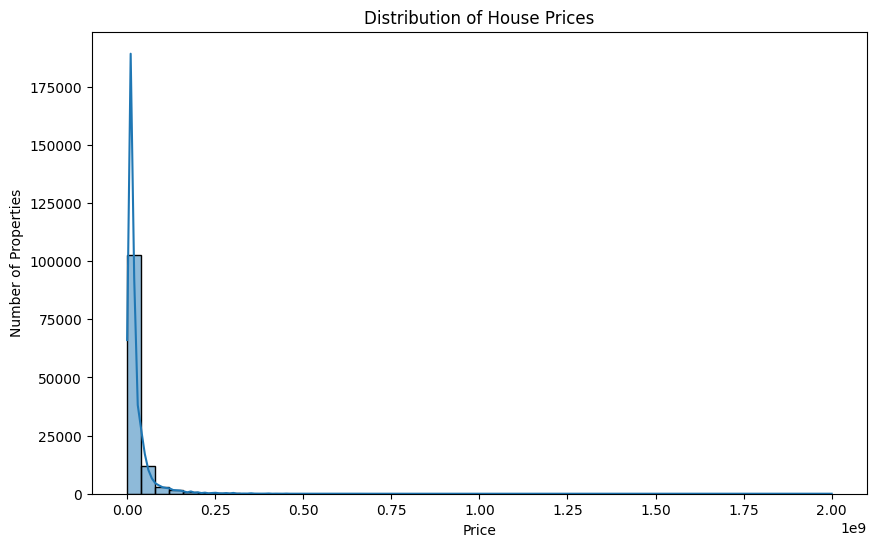

In [8]:
plt.figure(figsize=(10, 6))

sns.histplot(df["price"], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.show()

In [9]:
print(df["price"].describe())

count    1.206270e+05
mean     2.476874e+07
std      3.960018e+07
min      1.000000e+04
25%      7.400000e+06
50%      1.350000e+07
75%      2.600000e+07
max      2.000000e+09
Name: price, dtype: float64


Area vs Price Relation

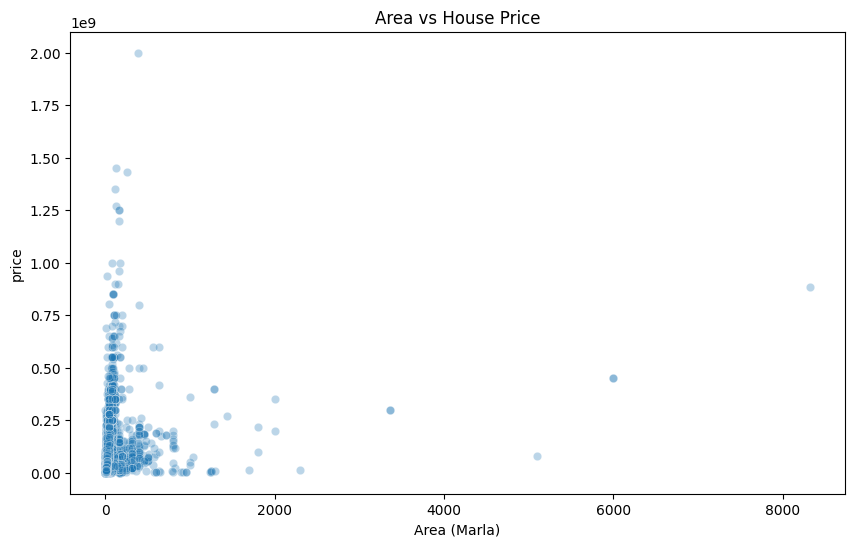

In [10]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Area_Marla",y="price",alpha=0.3)
plt.title("Area vs House Price")
plt.xlabel("Area (Marla)")
plt.ylabel("price")
plt.show()

City vs Price

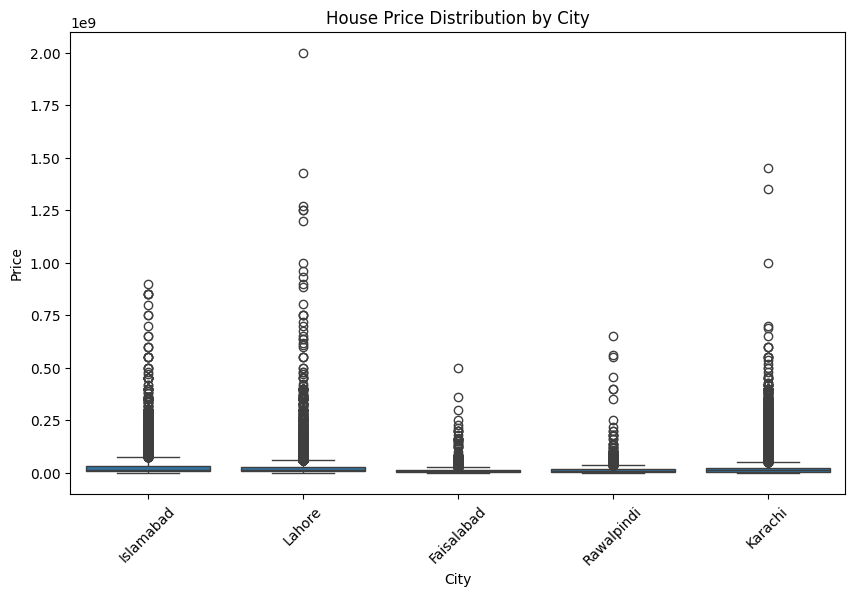

In [11]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df,x="city",y="price")
plt.title("House Price Distribution by City")
plt.xlabel("City")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.show()

Bedrooms vs House Price

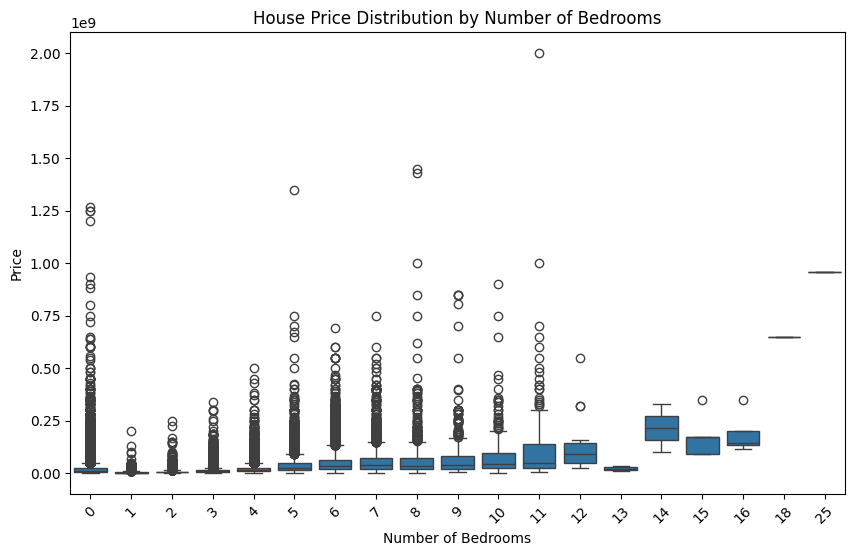

In [12]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df,x="bedrooms",y="price")
plt.title("House Price Distribution by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.show()

Bath vs Price

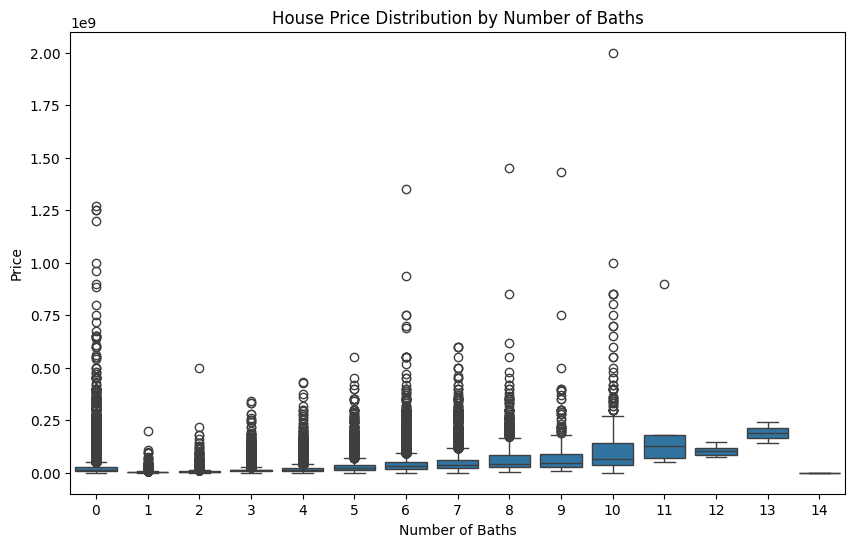

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="baths",
    y="price"
)

plt.title("House Price Distribution by Number of Baths")
plt.xlabel("Number of Baths")
plt.ylabel("Price")

plt.show()

Property type vs Price

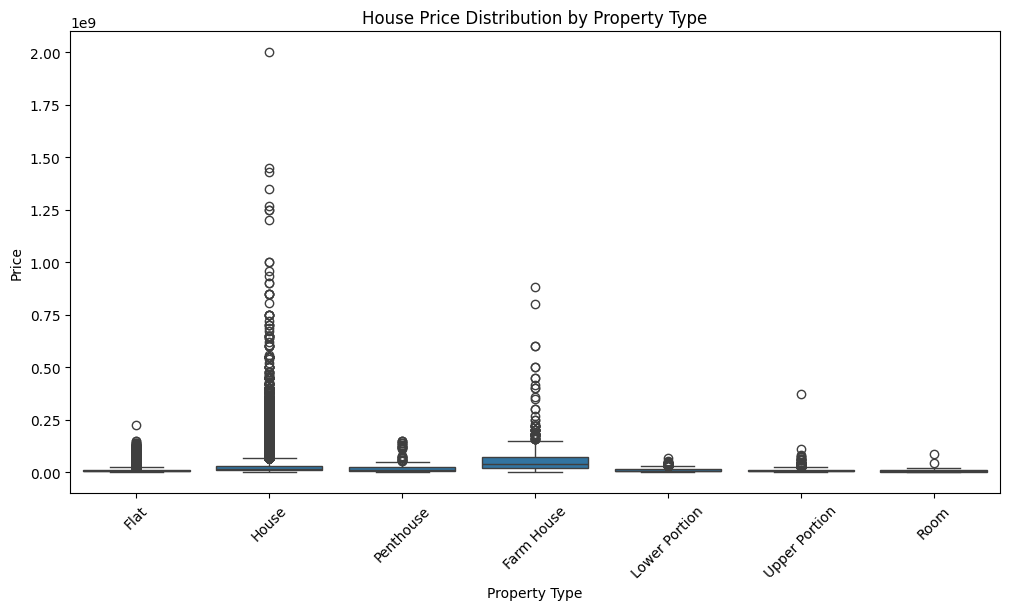

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="property_type",
    y="price"
)

plt.title("House Price Distribution by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price")
plt.xticks(rotation=45)

plt.show()

Correlation Analysis

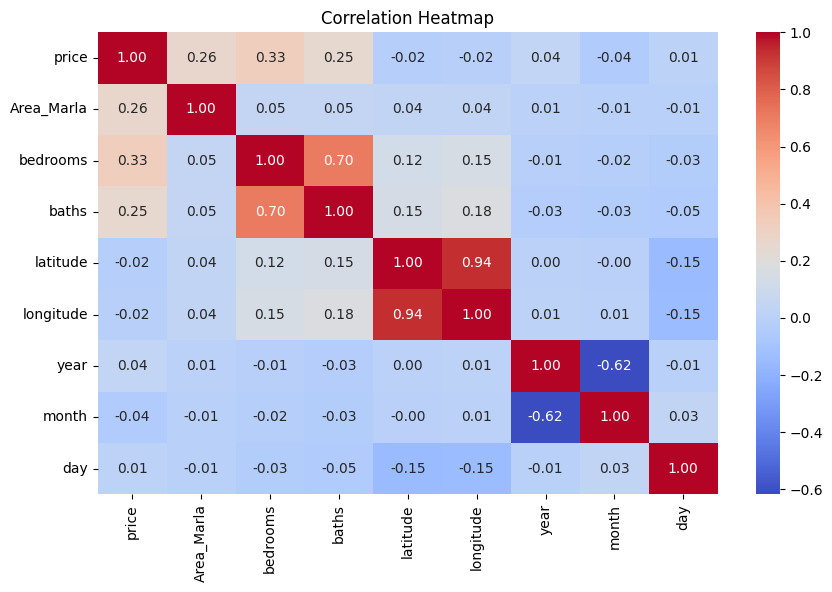

In [15]:
numeric_cols=[ "price",
    "Area_Marla",
    "bedrooms",
    "baths",
    "latitude",
    "longitude",
    "year",
    "month",
    "day"]
correlation=df[numeric_cols].corr()
plt.figure(figsize=(10,6))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

Outlier Investigation

In [16]:
#Price outliers
Q1=df["price"].quantile(0.25)
Q3=df["price"].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("Q1", Q1)
print("Q3", Q3)
print("Lower bound", lower_bound)
print("upper bound", upper_bound) 
outliers=df[(df["price"]<lower_bound) | (df["price"]>upper_bound).sum()]
print("Number of Price Outliers:",outliers.shape[0])

Q1 7400000.0
Q3 26000000.0
Lower bound -20500000.0
upper bound 53900000.0
Number of Price Outliers: 120627


In [17]:
print("Prices above upper bound:",
      (df["price"] > upper_bound).sum())

print("Prices below lower bound:",
      (df["price"] < lower_bound).sum())

print("Total potential outliers:",
      ((df["price"] > upper_bound) | (df["price"] < lower_bound)).sum())

Prices above upper bound: 11573
Prices below lower bound: 0
Total potential outliers: 11573


In [18]:
print(
    df[df["price"] > upper_bound][
        ["price", "property_type", "city", "Area_Marla", "bedrooms", "baths"]
    ].sort_values("price", ascending=False).head(20)
)

             price property_type       city  Area_Marla  bedrooms  baths
62648   2000000000         House     Lahore       384.0        11     10
42400   1450000000         House    Karachi       122.0         8      8
50268   1430000000         House     Lahore       260.0         8      9
56241   1350000000         House    Karachi       120.0         5      6
11587   1270000000         House     Lahore       128.0         0      0
72      1250000000         House     Lahore       160.0         0      0
54254   1250000000         House     Lahore       160.0         0      0
232     1200000000         House     Lahore       160.0         0      0
70143   1000000000         House     Lahore       180.0         8      0
40509   1000000000         House    Karachi        80.0        11     10
94980    960000000         House     Lahore       160.0        25      0
69870    935000000         House     Lahore        20.0         0      6
102720   900000000         House  Islamabad       1

Area_Marla Outliers

In [19]:
Q1_area = df["Area_Marla"].quantile(0.25)
Q3_area = df["Area_Marla"].quantile(0.75)

IQR_area = Q3_area - Q1_area

upper_area = Q3_area + 1.5 * IQR_area

print("Q1:", Q1_area)
print("Q3:", Q3_area)
print("IQR:", IQR_area)
print("Upper Bound:", upper_area)

print(
    "Potential Area Outliers:",
    (df["Area_Marla"] > upper_area).sum()
)

Q1: 4.8
Q3: 10.0
IQR: 5.2
Upper Bound: 17.8
Potential Area Outliers: 18840


In [20]:
area_outliers = df[df["Area_Marla"] > 17.8]

print(area_outliers[
    ["price", "property_type", "city", "Area_Marla", "bedrooms", "baths"]
].sort_values("Area_Marla", ascending=False).head(20))

            price property_type        city  Area_Marla  bedrooms  baths
5655    884000000    Farm House      Lahore      8320.0         0      0
54361   450000000    Farm House   Islamabad      6000.0         0      0
94662   450000000    Farm House   Islamabad      6000.0         0      0
109809   80000000    Farm House      Lahore      5100.0         0      0
32983   300000000    Farm House   Islamabad      3360.0         3      5
31948   300000000    Farm House   Islamabad      3360.0         3      5
108664   15000000          Flat   Islamabad      2302.0         3      3
3629    350000000    Farm House   Islamabad      2000.0         0      0
76408   200000000    Farm House      Lahore      2000.0         0      0
66100   220000000         House      Lahore      1800.0         5      9
32221   100000000    Farm House  Rawalpindi      1800.0         2      2
83088    11500000         House      Lahore      1700.0         3      4
16644   270000000    Farm House   Islamabad      14

In [21]:
print(
    df.groupby("property_type")["Area_Marla"]
    .agg(["count", "min", "median", "max"])
    .sort_values("max", ascending=False)
)

               count  min  median     max
property_type                            
Farm House       607  2.2   116.0  8320.0
Flat           28115  0.2     4.8  2302.0
House          87955  0.0     8.0  1800.0
Upper Portion   2628  0.4     5.0   240.0
Lower Portion   1002  0.7     5.3    56.0
Penthouse        295  1.8     8.4    40.0
Room              25  0.6     4.0    22.0


In [22]:
print(
    df[df["Area_Marla"] > 500][
        ["price", "property_type", "city", "Area_Marla", "bedrooms", "baths"]
    ].sort_values("Area_Marla", ascending=False).head(30)
)

            price property_type        city  Area_Marla  bedrooms  baths
5655    884000000    Farm House      Lahore      8320.0         0      0
54361   450000000    Farm House   Islamabad      6000.0         0      0
94662   450000000    Farm House   Islamabad      6000.0         0      0
109809   80000000    Farm House      Lahore      5100.0         0      0
31948   300000000    Farm House   Islamabad      3360.0         3      5
32983   300000000    Farm House   Islamabad      3360.0         3      5
108664   15000000          Flat   Islamabad      2302.0         3      3
76408   200000000    Farm House      Lahore      2000.0         0      0
3629    350000000    Farm House   Islamabad      2000.0         0      0
32221   100000000    Farm House  Rawalpindi      1800.0         2      2
66100   220000000         House      Lahore      1800.0         5      9
83088    11500000         House      Lahore      1700.0         3      4
16644   270000000    Farm House   Islamabad      14

In [23]:
suspicious_area = df[
    (
        (df["property_type"].isin(["Flat", "Lower Portion", "Upper Portion"])) &
        (df["Area_Marla"] > 100)
    )
]

print("Suspicious area records:", len(suspicious_area))

print(
    suspicious_area[
        ["price", "property_type", "city", "Area_Marla", "bedrooms", "baths"]
    ].sort_values("Area_Marla", ascending=False).head(30)
)

Suspicious area records: 14
            price  property_type       city  Area_Marla  bedrooms  baths
108664   15000000           Flat  Islamabad      2302.0         3      3
104126    6500000           Flat    Karachi      1300.0         3      3
38849     4500000           Flat     Lahore       920.0         2      2
104130    5500000           Flat    Karachi       900.0         2      2
104128    5500000           Flat    Karachi       800.0         2      2
109952    4400000           Flat     Lahore       600.0         1      1
100253    3000000           Flat  Islamabad       250.0         0      0
16599    13500000  Upper Portion    Karachi       240.0         3      3
120249   11500000  Upper Portion    Karachi       240.0         3      3
68824    32500000  Upper Portion    Karachi       224.0         4      4
90738      457000           Flat  Islamabad       172.0         1      1
73507   110000000  Upper Portion    Karachi       140.0         3      3
89974    32500000      

In [24]:
raw_df = pd.read_csv(r"D:\Summer\House Price Prediction\Raw data\Uncleaned_House_data.csv.csv")

print(raw_df[["property_type", "area", "price", "city"]].head())

  property_type       area     price       city
0          Flat    4 Marla  10000000  Islamabad
1          Flat  5.6 Marla   6900000  Islamabad
2         House    8 Marla  16500000  Islamabad
3         House    2 Kanal  43500000  Islamabad
4         House    8 Marla   7000000  Islamabad


In [25]:
print(
    raw_df[raw_df["area"].str.contains("12000|2302|1300|950|920|900|800|700", 
                                      na=False)][
        ["property_type", "area", "price", "city"]
    ]
)

       property_type       area  price        city
165150          Flat  800 Kanal  16000  Rawalpindi


In [26]:
kanal_data = raw_df[raw_df["area"].str.contains("Kanal", na=False)].copy()

kanal_data["Kanal_Size"] = kanal_data["area"].str.extract(
    r"([\d.]+)"
)[0].astype(float)

print("Maximum Kanal:", kanal_data["Kanal_Size"].max())

print(
    kanal_data.sort_values("Kanal_Size", ascending=False)[
        ["property_type", "area", "price", "city"]
    ].head(20)
)

Maximum Kanal: 800.0
        property_type         area      price        city
165150           Flat    800 Kanal      16000  Rawalpindi
126842  Lower Portion    650 Kanal      13000  Rawalpindi
68989   Lower Portion    600 Kanal    2200000     Karachi
168178  Upper Portion    500 Kanal      70000   Islamabad
125631          House    500 Kanal     300000   Islamabad
167017  Lower Portion    500 Kanal     115000   Islamabad
30276   Upper Portion    500 Kanal      35000   Islamabad
143744  Lower Portion    500 Kanal      70000   Islamabad
7711       Farm House    416 Kanal  884000000      Lahore
74447      Farm House    300 Kanal  450000000   Islamabad
129041     Farm House    300 Kanal  450000000   Islamabad
151417     Farm House    255 Kanal   80000000      Lahore
43783      Farm House    168 Kanal  300000000   Islamabad
45173      Farm House    168 Kanal  300000000   Islamabad
149501           Flat  115.1 Kanal   15000000   Islamabad
145107           Flat    105 Kanal     120000  Rawa

In [27]:
non_farm_large = df[
    (df["property_type"] != "Farm House") &
    (df["Area_Marla"] > 100)
]

print("Non-Farm-House > 100 Marla:", len(non_farm_large))

print(
    non_farm_large[
        ["price", "property_type", "city", "Area_Marla", "bedrooms", "baths"]
    ].sort_values("Area_Marla", ascending=False).head(30)
)

Non-Farm-House > 100 Marla: 184
            price property_type        city  Area_Marla  bedrooms  baths
108664   15000000          Flat   Islamabad      2302.0         3      3
66100   220000000         House      Lahore      1800.0         5      9
83088    11500000         House      Lahore      1700.0         3      4
104126    6500000          Flat     Karachi      1300.0         3      3
78892   230000000         House   Islamabad      1282.0         0      0
11755     6800000         House  Rawalpindi      1250.0         3      4
96776     6800000         House  Rawalpindi      1250.0         2      3
45577     4800000         House  Rawalpindi      1250.0         2      2
89137     5000000         House  Rawalpindi      1234.0         2      2
104397    4750000         House      Lahore       950.0         2      2
104400    4750000         House      Lahore       950.0         2      2
38849     4500000          Flat      Lahore       920.0         2      2
104130    5500000  

In [28]:
very_large_non_farm = df[
    (df["property_type"] != "Farm House") &
    (df["Area_Marla"] > 500)
]

print("Very large non-Farm-House records:", len(very_large_non_farm))

print(
    very_large_non_farm[
        ["price", "property_type", "city", "Area_Marla", "bedrooms", "baths"]
    ].sort_values("Area_Marla", ascending=False)
)

Very large non-Farm-House records: 23
            price property_type        city  Area_Marla  bedrooms  baths
108664   15000000          Flat   Islamabad      2302.0         3      3
66100   220000000         House      Lahore      1800.0         5      9
83088    11500000         House      Lahore      1700.0         3      4
104126    6500000          Flat     Karachi      1300.0         3      3
78892   230000000         House   Islamabad      1282.0         0      0
11755     6800000         House  Rawalpindi      1250.0         3      4
45577     4800000         House  Rawalpindi      1250.0         2      2
96776     6800000         House  Rawalpindi      1250.0         2      3
89137     5000000         House  Rawalpindi      1234.0         2      2
104400    4750000         House      Lahore       950.0         2      2
104397    4750000         House      Lahore       950.0         2      2
38849     4500000          Flat      Lahore       920.0         2      2
104130    550

In [29]:
large_area = df[
    (df["property_type"] != "Farm House") &
    (df["Area_Marla"] > 500)
].copy()

large_area["Price_per_Marla"] = (
    large_area["price"] / large_area["Area_Marla"]
)

print(
    large_area[
        ["price", "property_type", "city",
         "Area_Marla", "Price_per_Marla",
         "bedrooms", "baths"]
    ].sort_values("Area_Marla", ascending=False)
)

            price property_type        city  Area_Marla  Price_per_Marla  \
108664   15000000          Flat   Islamabad      2302.0      6516.072980   
66100   220000000         House      Lahore      1800.0    122222.222222   
83088    11500000         House      Lahore      1700.0      6764.705882   
104126    6500000          Flat     Karachi      1300.0      5000.000000   
78892   230000000         House   Islamabad      1282.0    179407.176287   
11755     6800000         House  Rawalpindi      1250.0      5440.000000   
45577     4800000         House  Rawalpindi      1250.0      3840.000000   
96776     6800000         House  Rawalpindi      1250.0      5440.000000   
89137     5000000         House  Rawalpindi      1234.0      4051.863857   
104400    4750000         House      Lahore       950.0      5000.000000   
104397    4750000         House      Lahore       950.0      5000.000000   
38849     4500000          Flat      Lahore       920.0      4891.304348   
104130    55

In [30]:
suspicious_area = large_area[
    large_area["Price_per_Marla"] < 1000
]

print(
    suspicious_area[
        ["price", "property_type", "city",
         "Area_Marla", "Price_per_Marla",
         "bedrooms", "baths"]
    ].sort_values("Price_per_Marla")
)

Empty DataFrame
Columns: [price, property_type, city, Area_Marla, Price_per_Marla, bedrooms, baths]
Index: []


In [31]:
# Check original area values for the suspicious records
raw_df = pd.read_csv(r"D:\Summer\House Price Prediction\Raw data\Uncleaned_House_data.csv.csv")

for price, city in [(13000, "Rawalpindi"),
                    (2200000, "Karachi"),
                    (600000, "Lahore")]:
    
    result = raw_df[
        (raw_df["price"] == price) &
        (raw_df["city"] == city)
    ]

    print("\n", result[
        ["property_type", "area", "price", "city",
         "bedrooms", "baths"]
    ])


         property_type       area  price        city  bedrooms  baths
2439            House    4 Marla  13000  Rawalpindi         3      1
7065    Lower Portion    5 Marla  13000  Rawalpindi         2      0
12440            Flat    5 Marla  13000  Rawalpindi         2      1
19722   Upper Portion  2.5 Marla  13000  Rawalpindi         3      1
22011            Flat  5.3 Marla  13000  Rawalpindi         2      2
22026            Flat  3.6 Marla  13000  Rawalpindi         2      2
22027            Flat  3.1 Marla  13000  Rawalpindi         2      2
22329   Upper Portion    5 Marla  13000  Rawalpindi         0      0
23292   Upper Portion    6 Marla  13000  Rawalpindi         2      2
23531           House    6 Marla  13000  Rawalpindi         3      1
33924   Lower Portion    7 Marla  13000  Rawalpindi         4      2
34684   Upper Portion    5 Marla  13000  Rawalpindi         2      2
35769   Lower Portion    2 Marla  13000  Rawalpindi         1      1
36034            Flat    2 Marla

In [32]:
# Exact suspicious records
checks = [
    (13000, "Rawalpindi", "Flat", 2, 2),
    (2200000, "Karachi", "Lower Portion", 0, 0),
    (600000, "Lahore", "Flat", 2, 2)
]

for price, city, property_type, bedrooms, baths in checks:
    result = raw_df[
        (raw_df["price"] == price) &
        (raw_df["city"] == city) &
        (raw_df["property_type"] == property_type) &
        (raw_df["bedrooms"] == bedrooms) &
        (raw_df["baths"] == baths)
    ]

    print("\n---", price, city, property_type, "---")
    print(result[[
        "property_type", "area", "price",
        "city", "bedrooms", "baths"
    ]].to_string(index=False))


--- 13000 Rawalpindi Flat ---
property_type      area  price       city  bedrooms  baths
         Flat 5.3 Marla  13000 Rawalpindi         2      2
         Flat 3.6 Marla  13000 Rawalpindi         2      2
         Flat 3.1 Marla  13000 Rawalpindi         2      2
         Flat   3 Marla  13000 Rawalpindi         2      2
         Flat   2 Marla  13000 Rawalpindi         2      2
         Flat  35 Kanal  13000 Rawalpindi         2      2

--- 2200000 Karachi Lower Portion ---
property_type      area   price    city  bedrooms  baths
Lower Portion 600 Kanal 2200000 Karachi         0      0

--- 600000 Lahore Flat ---
property_type       area  price   city  bedrooms  baths
         Flat  4.2 Marla 600000 Lahore         2      2
         Flat  4.2 Marla 600000 Lahore         2      2
         Flat  4.2 Marla 600000 Lahore         2      2
         Flat 47.5 Kanal 600000 Lahore         2      2


In [33]:
suspicious_indices = [95454, 50390, 100880]

df = df.drop(index=suspicious_indices).reset_index(drop=True)

print("New shape:", df.shape)

New shape: (120624, 16)


In [34]:
df.to_csv(r"D:\Summer\House Price Prediction\Raw data\cleaned_house_price_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [35]:
high_bedrooms = df[df["bedrooms"] > 15]

print("Records with bedrooms > 15:", len(high_bedrooms))

print(
    high_bedrooms[
        ["price", "property_type", "city",
         "Area_Marla", "bedrooms", "baths"]
    ].sort_values("bedrooms", ascending=False)
)

Records with bedrooms > 15: 6
           price property_type       city  Area_Marla  bedrooms  baths
94979  960000000         House     Lahore       160.0        25      0
50657  650000000         House     Lahore        92.0        18      0
12238  140000000         House  Islamabad        40.0        16      0
63343  115000000         House  Islamabad        24.0        16      0
70141  350000000         House     Lahore        64.0        16      0
96257  150000000         House    Karachi        24.0        16      6


In [36]:
high_bedrooms_raw = raw_df[
    raw_df["bedrooms"] > 15
]

print(
    high_bedrooms_raw[
        ["property_type", "area", "price",
         "city", "bedrooms", "baths"]
    ].sort_values("bedrooms", ascending=False)
    .to_string(index=False)
)

property_type      area     price       city  bedrooms  baths
        House 6.6 Kanal   2500000    Karachi        68      0
        House   2 Kanal   1300000 Rawalpindi        28      0
        House   2 Kanal   1300000 Rawalpindi        28      0
        House   2 Kanal   1300000 Rawalpindi        28      0
        House   2 Kanal   1300000 Rawalpindi        28      0
        House   3 Kanal  80000000 Rawalpindi        27      0
        House   3 Kanal    550000    Karachi        25      0
        House   8 Kanal 960000000     Lahore        25      0
        House   3 Kanal    900000    Karachi        25      0
        House 1.2 Kanal    300000  Islamabad        21      0
        House 2.4 Kanal    550000  Islamabad        18     10
        House 4.6 Kanal 650000000     Lahore        18      0
        House 3.2 Kanal 350000000     Lahore        16      0
        House 1.2 Kanal 115000000  Islamabad        16      0
        House   2 Kanal 140000000  Islamabad        16      0
        

In [37]:
bedroom_68 = raw_df[
    (raw_df["bedrooms"] == 68) &
    (raw_df["city"] == "Karachi")
]

print(
    bedroom_68[
        ["property_type", "area", "price",
         "city", "bedrooms", "baths"]
    ].to_string(index=False)
)

property_type      area   price    city  bedrooms  baths
        House 6.6 Kanal 2500000 Karachi        68      0


In [38]:
df = df.drop(index=105442).reset_index(drop=True)

print("New shape:", df.shape)

New shape: (120623, 16)


In [39]:
df.to_csv(r"D:\Summer\House Price Prediction\Raw data\cleaned_house_price_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [40]:
high_baths = df[df["baths"] > 10]

print("Records with baths > 10:", len(high_baths))

print(
    high_baths[
        ["price", "property_type", "city",
         "Area_Marla", "bedrooms", "baths"]
    ].sort_values("baths", ascending=False)
)

Records with baths > 10: 14
            price property_type       city  Area_Marla  bedrooms  baths
115017     250000         House  Islamabad        30.0        10     14
65527   240000000         House    Karachi        40.0        10     13
113428  140000000         House    Karachi        30.0        10     13
82507    75000000         House  Islamabad        20.0        10     12
81854   112500000         House  Islamabad        20.0         9     12
70483   145000000         House  Islamabad        26.0         9     12
113866   80000000         House    Karachi        16.0        10     12
108893   90000000         House     Lahore        40.0        10     12
84245   120000000         House    Karachi        40.0         9     12
6489    125000000         House     Lahore        40.0        11     11
65713   180000000         House    Karachi        19.0         9     11
15275    70000000         House  Islamabad        20.0        11     11
102717  900000000         House  Isl

In [41]:
suspicious_bath = df[
    (df["Area_Marla"] < 2) &
    (df["baths"] > 10)
]

print(
    suspicious_bath[
        ["price", "property_type", "city",
         "Area_Marla", "bedrooms", "baths"]
    ].to_string()
)

Empty DataFrame
Columns: [price, property_type, city, Area_Marla, bedrooms, baths]
Index: []


In [42]:
bath_check = raw_df[
    (raw_df["price"] == 70000000) &
    (raw_df["city"] == "Karachi") &
    (raw_df["property_type"] == "House") &
    (raw_df["bedrooms"] == 8) &
    (raw_df["baths"] == 12)
]

print(
    bath_check[
        ["property_type", "area", "price",
         "city", "bedrooms", "baths"]
    ].to_string(index=False)
)

property_type      area    price    city  bedrooms  baths
        House 1.3 Marla 70000000 Karachi         8     12


In [43]:
df = df.drop(index=109218).reset_index(drop=True)

print("New shape:", df.shape)

New shape: (120622, 16)


In [44]:
df.to_csv(r"D:\Summer\House Price Prediction\Raw data\cleaned_house_price_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [45]:
print("Bedrooms = 0:", (df["bedrooms"] == 0).sum())
print("Baths = 0:", (df["baths"] == 0).sum())

print("\nBedrooms = 0 by Property Type:")
print(df[df["bedrooms"] == 0]["property_type"].value_counts())

print("\nBaths = 0 by Property Type:")
print(df[df["baths"] == 0]["property_type"].value_counts())

Bedrooms = 0: 13112
Baths = 0: 27544

Bedrooms = 0 by Property Type:
property_type
House            9966
Flat             2294
Farm House        369
Upper Portion     323
Lower Portion     114
Penthouse          39
Room                7
Name: count, dtype: int64

Baths = 0 by Property Type:
property_type
House            20279
Flat              5773
Upper Portion      701
Farm House         401
Lower Portion      298
Penthouse           82
Room                10
Name: count, dtype: int64


In [46]:
zero_bed = df[df["bedrooms"] == 0]

print("Bedrooms = 0 Price Statistics:")
print(zero_bed["price"].describe())

print("\nBedrooms = 0 Area Statistics:")
print(zero_bed["Area_Marla"].describe())


zero_bath = df[df["baths"] == 0]

print("\nBaths = 0 Price Statistics:")
print(zero_bath["price"].describe())

print("\nBaths = 0 Area Statistics:")
print(zero_bath["Area_Marla"].describe())

Bedrooms = 0 Price Statistics:
count    1.311200e+04
mean     2.540421e+07
std      5.278146e+07
min      2.300000e+04
25%      6.200000e+06
50%      1.100000e+07
75%      2.300000e+07
max      1.270000e+09
Name: price, dtype: float64

Bedrooms = 0 Area Statistics:
count    13112.000000
mean        15.914613
std        123.530978
min          0.000000
25%          4.000000
50%          5.000000
75%         10.000000
max       8320.000000
Name: Area_Marla, dtype: float64

Baths = 0 Price Statistics:
count    2.754400e+04
mean     2.591045e+07
std      4.717482e+07
min      2.300000e+04
25%      6.800000e+06
50%      1.250000e+07
75%      2.500000e+07
max      1.270000e+09
Name: price, dtype: float64

Baths = 0 Area Statistics:
count    27544.000000
mean        12.813212
std         86.136651
min          0.000000
25%          4.300000
50%          5.800000
75%         10.000000
max       8320.000000
Name: Area_Marla, dtype: float64


In [47]:
df["Price_per_Marla"] = df["price"] / df["Area_Marla"]

print(df["Price_per_Marla"].describe())

count    1.206220e+05
mean              inf
std               NaN
min      1.388889e+02
25%      1.477273e+06
50%      2.000000e+06
75%      2.682219e+06
max               inf
Name: Price_per_Marla, dtype: float64


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


In [48]:
print("Area_Marla = 0:", (df["Area_Marla"] == 0).sum())

print("\nZero Area records:")
print(
    df[df["Area_Marla"] == 0][
        ["price","Area Type", "Area Size",
         "Area_Marla", "property_type", "city"]
    ].head(20)
)

Area_Marla = 0: 9

Zero Area records:
           price Area Type  Area Size  Area_Marla property_type        city
22532    4400000     Marla        0.0         0.0         House     Karachi
27877   12500000     Marla        0.0         0.0         House      Lahore
84669   18000000     Marla        0.0         0.0         House      Lahore
94070   16500000     Marla        0.0         0.0         House   Islamabad
95667   31500000     Marla        0.0         0.0         House   Islamabad
95871    2200000     Marla        0.0         0.0         House      Lahore
115391   4500000     Marla        0.0         0.0         House      Lahore
118957  19500000     Marla        0.0         0.0         House      Lahore
119703   5000000     Marla        0.0         0.0         House  Rawalpindi


In [49]:
df = df[df["Area_Marla"] > 0].copy()

print("New Data Shape:", df.shape)
print("Zero Area:", (df["Area_Marla"] == 0).sum())

New Data Shape: (120613, 17)
Zero Area: 0


In [50]:
df["Price_per_Marla"] = df["price"] / df["Area_Marla"]

print(df["Price_per_Marla"].describe())

count    1.206130e+05
mean     2.314085e+06
std      5.363725e+06
min      1.388889e+02
25%      1.477273e+06
50%      2.000000e+06
75%      2.681159e+06
max      1.500000e+09
Name: Price_per_Marla, dtype: float64


In [51]:
print("Lowest Price per Marla:")
print(df.nsmallest(10, "Price_per_Marla")[
    ["property_type", "price", "location", "city", "Area_Marla", "Price_per_Marla"]
])

print("\nHighest Price per Marla:")
print(df.nlargest(10, "Price_per_Marla")[
    ["property_type", "price", "location", "city", "Area_Marla", "Price_per_Marla"]
])

Lowest Price per Marla:
        property_type  price                location        city  Area_Marla  \
89161      Farm House  25000                   Cantt      Lahore       180.0   
115623          House  70000                    G-11   Islamabad       160.0   
91400            Room  20000             DHA Defence      Lahore        20.0   
104668           Flat  10000         University Road     Karachi         7.6   
95022   Upper Portion  25000  Gulraiz Housing Scheme  Rawalpindi        12.0   
91394   Upper Portion  90000             DHA Defence      Lahore        40.0   
88361   Upper Portion  23000              Wapda Town      Lahore        10.0   
93011            Room  23000             DHA Defence      Lahore        10.0   
91578   Upper Portion  50000             DHA Defence      Lahore        20.0   
117445  Upper Portion  50000  Bahria Town Rawalpindi  Rawalpindi        20.0   

        Price_per_Marla  
89161        138.888889  
115623       437.500000  
91400       1000.

In [52]:
print("Highest Price per Marla:")
print(
    df.nlargest(10, "Price_per_Marla")[
        [
            "property_type",
            "price",
            "location",
            "city",
            "Area_Marla",
            "Price_per_Marla",
            "bedrooms",
            "baths"
        ]
    ].to_string()
)

Highest Price per Marla:
       property_type      price            location       city  Area_Marla  Price_per_Marla  bedrooms  baths
71322          House  300000000                 F-8  Islamabad         0.2     1.500000e+09         6      6
95039          House   82500000         DHA Defence     Lahore         0.1     8.250000e+08         5      7
96221          House   45000000         DHA Defence     Lahore         0.1     4.500000e+08         5      6
93251          House   25000000  PWD Housing Scheme  Islamabad         0.1     2.500000e+08         0      0
119292         House   45000000                E-11  Islamabad         0.4     1.125000e+08         6      7
31501          House  690000000         DHA Defence    Karachi         8.0     8.625000e+07         6      6
118119         House   75000000         DHA Defence     Lahore         1.0     7.500000e+07         5      5
57870          House   69000000         DHA Defence     Lahore         1.0     6.900000e+07         5  

In [53]:
print(
    df.loc[
        df["Price_per_Marla"].nlargest(10).index,
        [
            "property_type",
            "price",
            "Area_Marla",
            "Area Type",
            "location",
            "city",
            "bedrooms",
            "baths"
        ]
    ].to_string()
)

       property_type      price  Area_Marla Area Type            location       city  bedrooms  baths
71322          House  300000000         0.2     Marla                 F-8  Islamabad         6      6
95039          House   82500000         0.1     Marla         DHA Defence     Lahore         5      7
96221          House   45000000         0.1     Marla         DHA Defence     Lahore         5      6
93251          House   25000000         0.1     Marla  PWD Housing Scheme  Islamabad         0      0
119292         House   45000000         0.4     Marla                E-11  Islamabad         6      7
31501          House  690000000         8.0     Marla         DHA Defence    Karachi         6      6
118119         House   75000000         1.0     Marla         DHA Defence     Lahore         5      5
57870          House   69000000         1.0     Marla         DHA Defence     Lahore         5      7
19413          House  275000000         4.0     Marla         DHA Defence    Karac

In [54]:
print("Price per Marla Statistics:")
print(df["Price_per_Marla"].describe())

print("\nPrice per Marla > 10 Million:")
print((df["Price_per_Marla"] > 10_000_000).sum())

print("\nPrice per Marla > 50 Million:")
print((df["Price_per_Marla"] > 50_000_000).sum())

print("\nPrice per Marla > 100 Million:")
print((df["Price_per_Marla"] > 100_000_000).sum())

Price per Marla Statistics:
count    1.206130e+05
mean     2.314085e+06
std      5.363725e+06
min      1.388889e+02
25%      1.477273e+06
50%      2.000000e+06
75%      2.681159e+06
max      1.500000e+09
Name: Price_per_Marla, dtype: float64

Price per Marla > 10 Million:
262

Price per Marla > 50 Million:
9

Price per Marla > 100 Million:
5


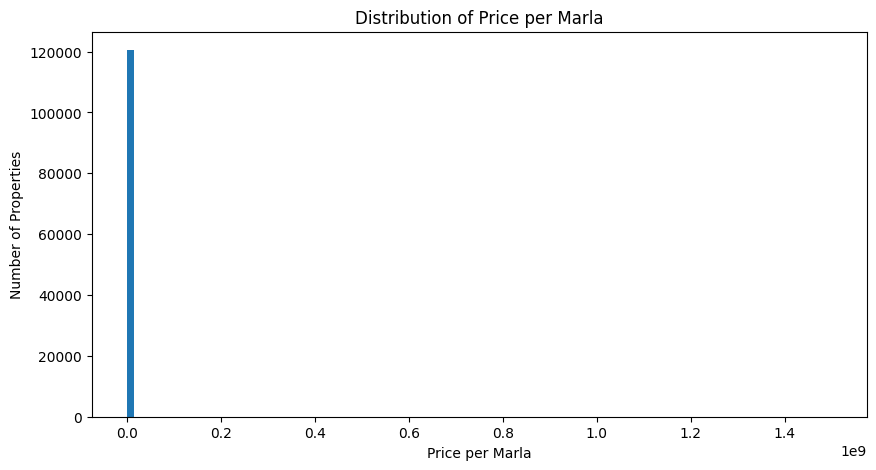

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["Price_per_Marla"], bins=100)
plt.xlabel("Price per Marla")
plt.ylabel("Number of Properties")
plt.title("Distribution of Price per Marla")
plt.show()

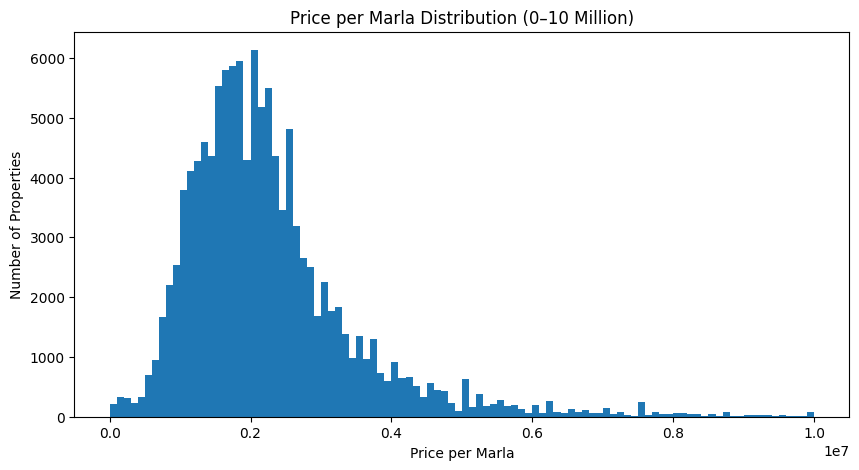

In [56]:
plt.figure(figsize=(10, 5))
plt.hist(df["Price_per_Marla"], bins=100, range=(0, 10_000_000))
plt.xlabel("Price per Marla")
plt.ylabel("Number of Properties")
plt.title("Price per Marla Distribution (0–10 Million)")
plt.show()

In [57]:
print(df["property_type"].value_counts())

property_type
House            87942
Flat             28115
Upper Portion     2627
Lower Portion     1002
Farm House         607
Penthouse          295
Room                25
Name: count, dtype: int64


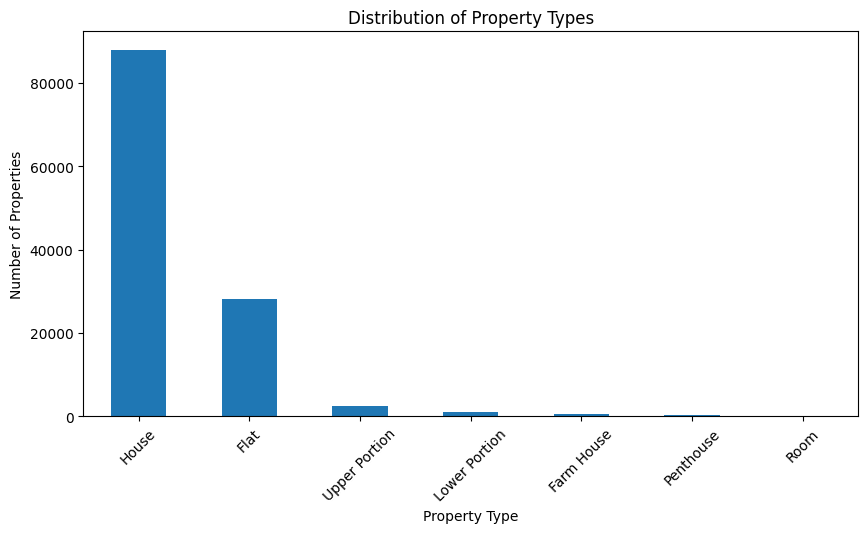

In [58]:
plt.figure(figsize=(10, 5))

df["property_type"].value_counts().plot(kind="bar")

plt.xlabel("Property Type")
plt.ylabel("Number of Properties")
plt.title("Distribution of Property Types")
plt.xticks(rotation=45)
plt.show()

In [59]:
print(df["city"].value_counts())

city
Karachi       46654
Lahore        41417
Islamabad     16101
Rawalpindi    11986
Faisalabad     4455
Name: count, dtype: int64


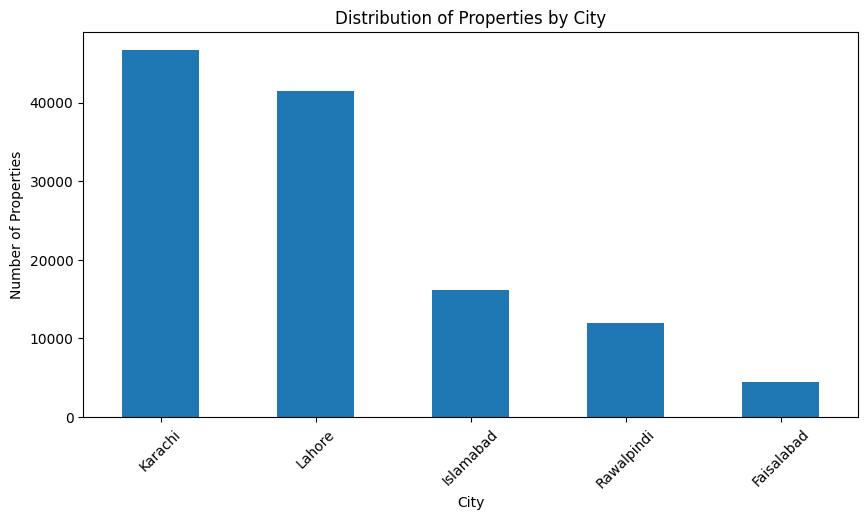

In [60]:
plt.figure(figsize=(10, 5))

df["city"].value_counts().plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Number of Properties")
plt.title("Distribution of Properties by City")
plt.xticks(rotation=45)
plt.show()

In [61]:
print(df["province_name"].value_counts())

province_name
Punjab               57858
Sindh                46654
Islamabad Capital    16101
Name: count, dtype: int64


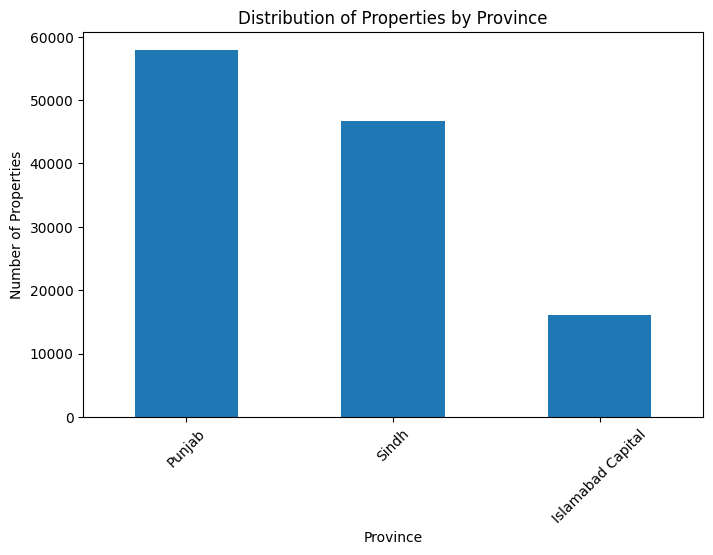

In [62]:
plt.figure(figsize=(8, 5))

df["province_name"].value_counts().plot(kind="bar")

plt.xlabel("Province")
plt.ylabel("Number of Properties")
plt.title("Distribution of Properties by Province")
plt.xticks(rotation=45)
plt.show()